# PLot Kinematics PRed vs Real

Loading dataset...
Total samples loaded: 62506
Available time range: 0.0000 s to 525.1116 s

Zoom range:
Start time: 230.84579656353 s
End time  : 231.240648897706 s
Samples   : 48

Generating X Position plot...


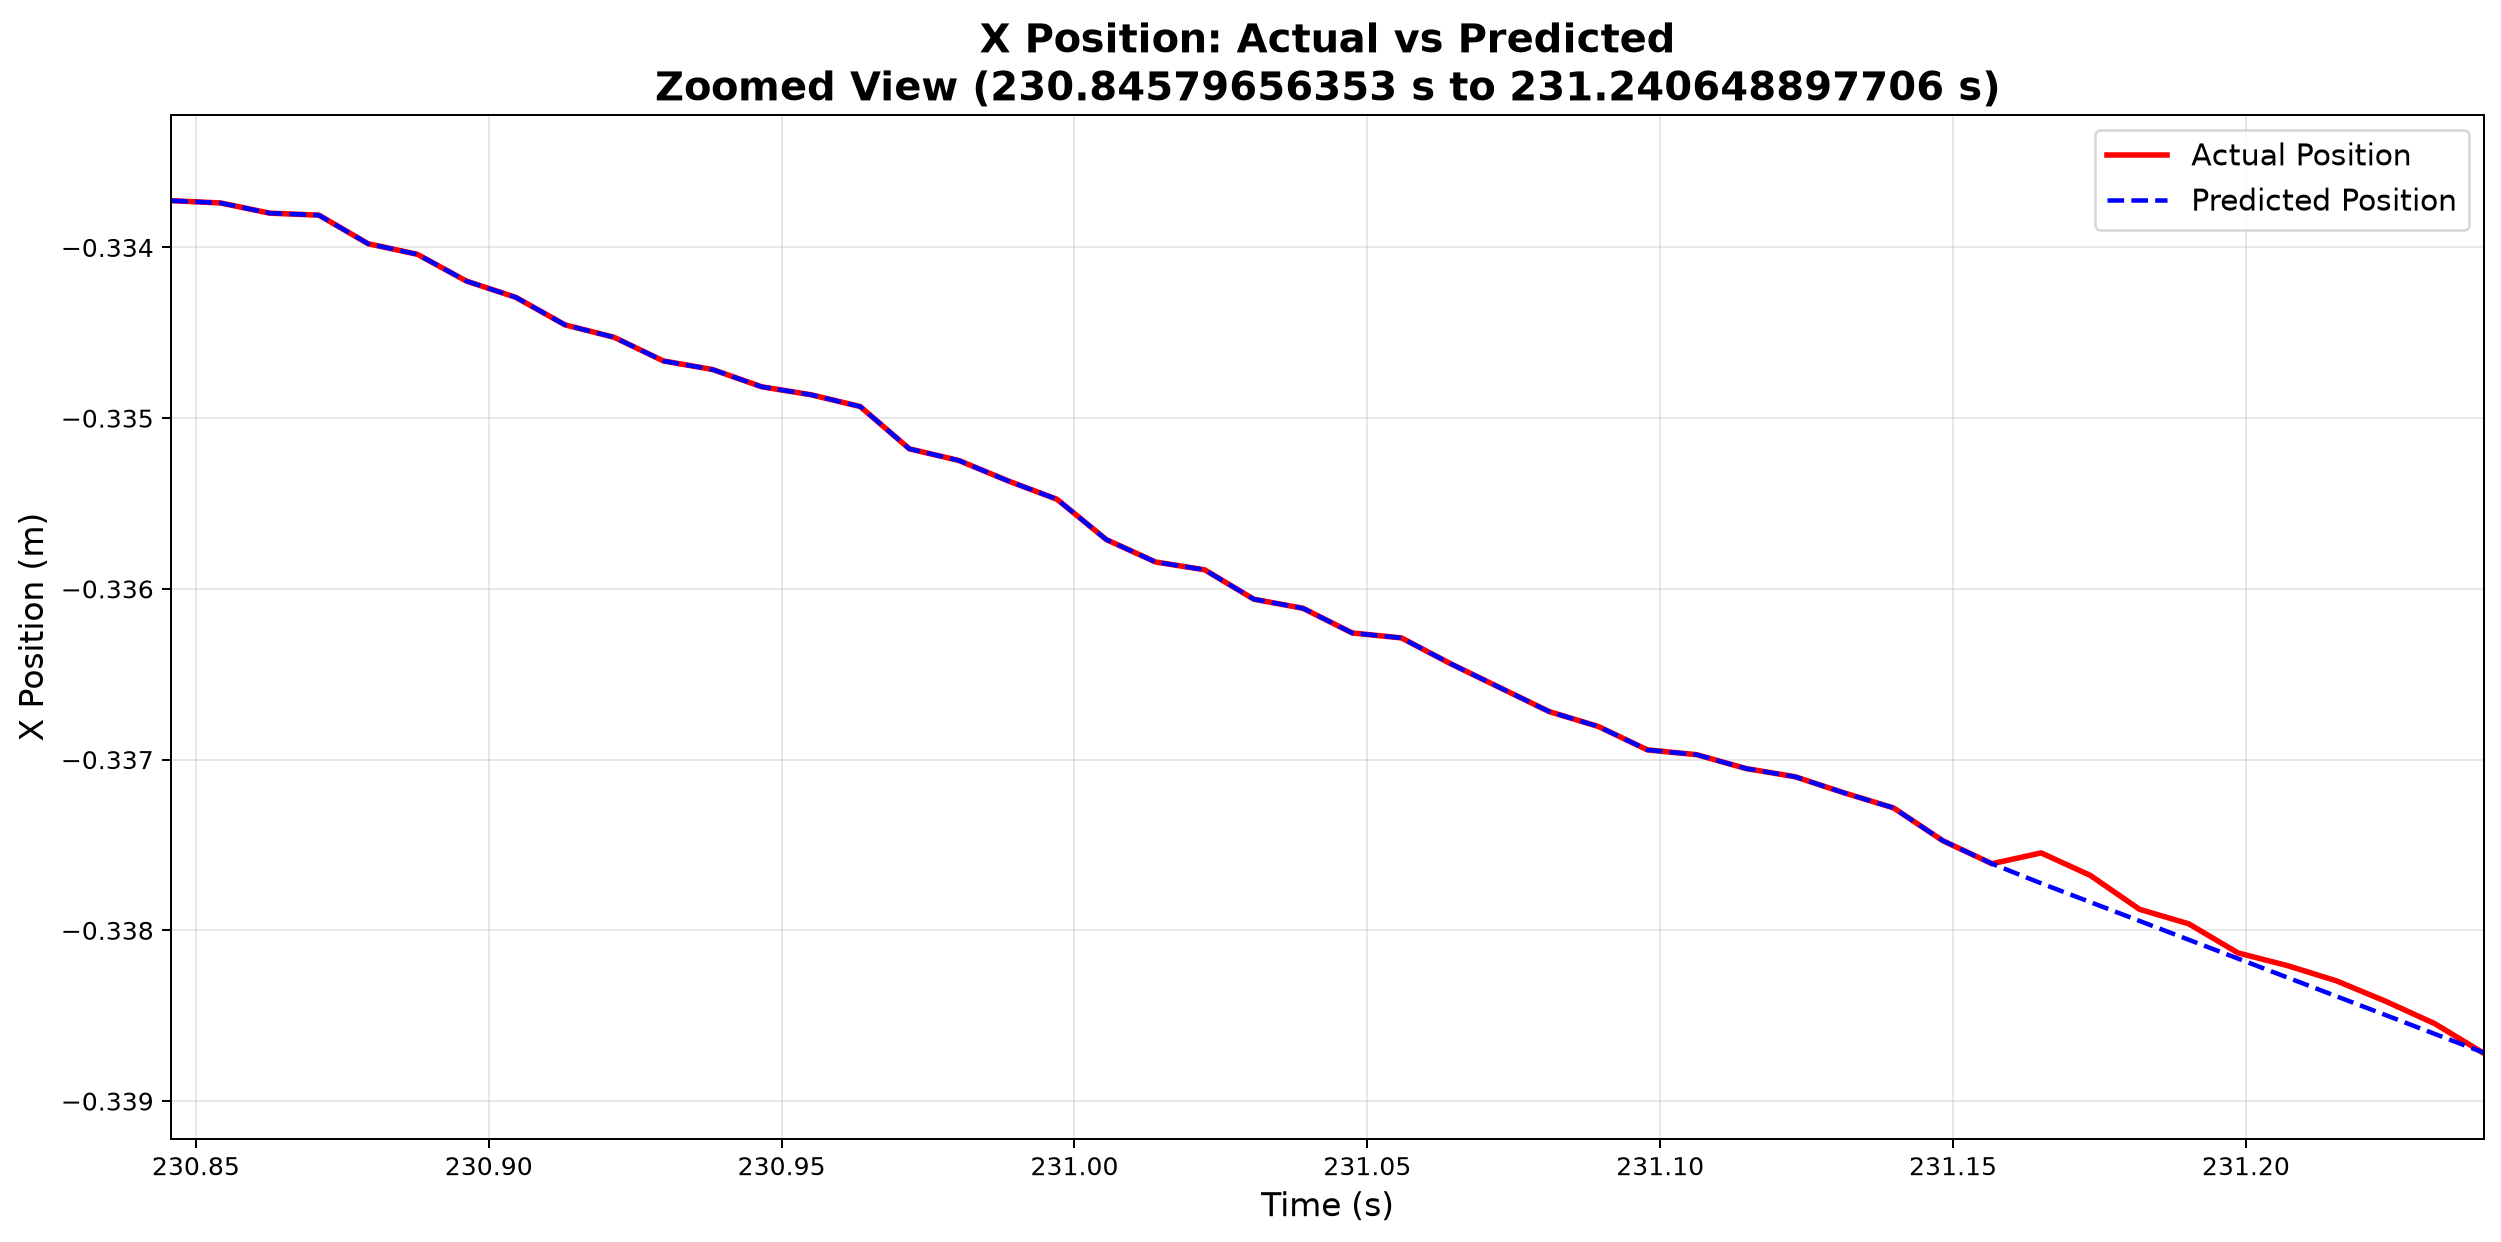

Generating Y Position plot...


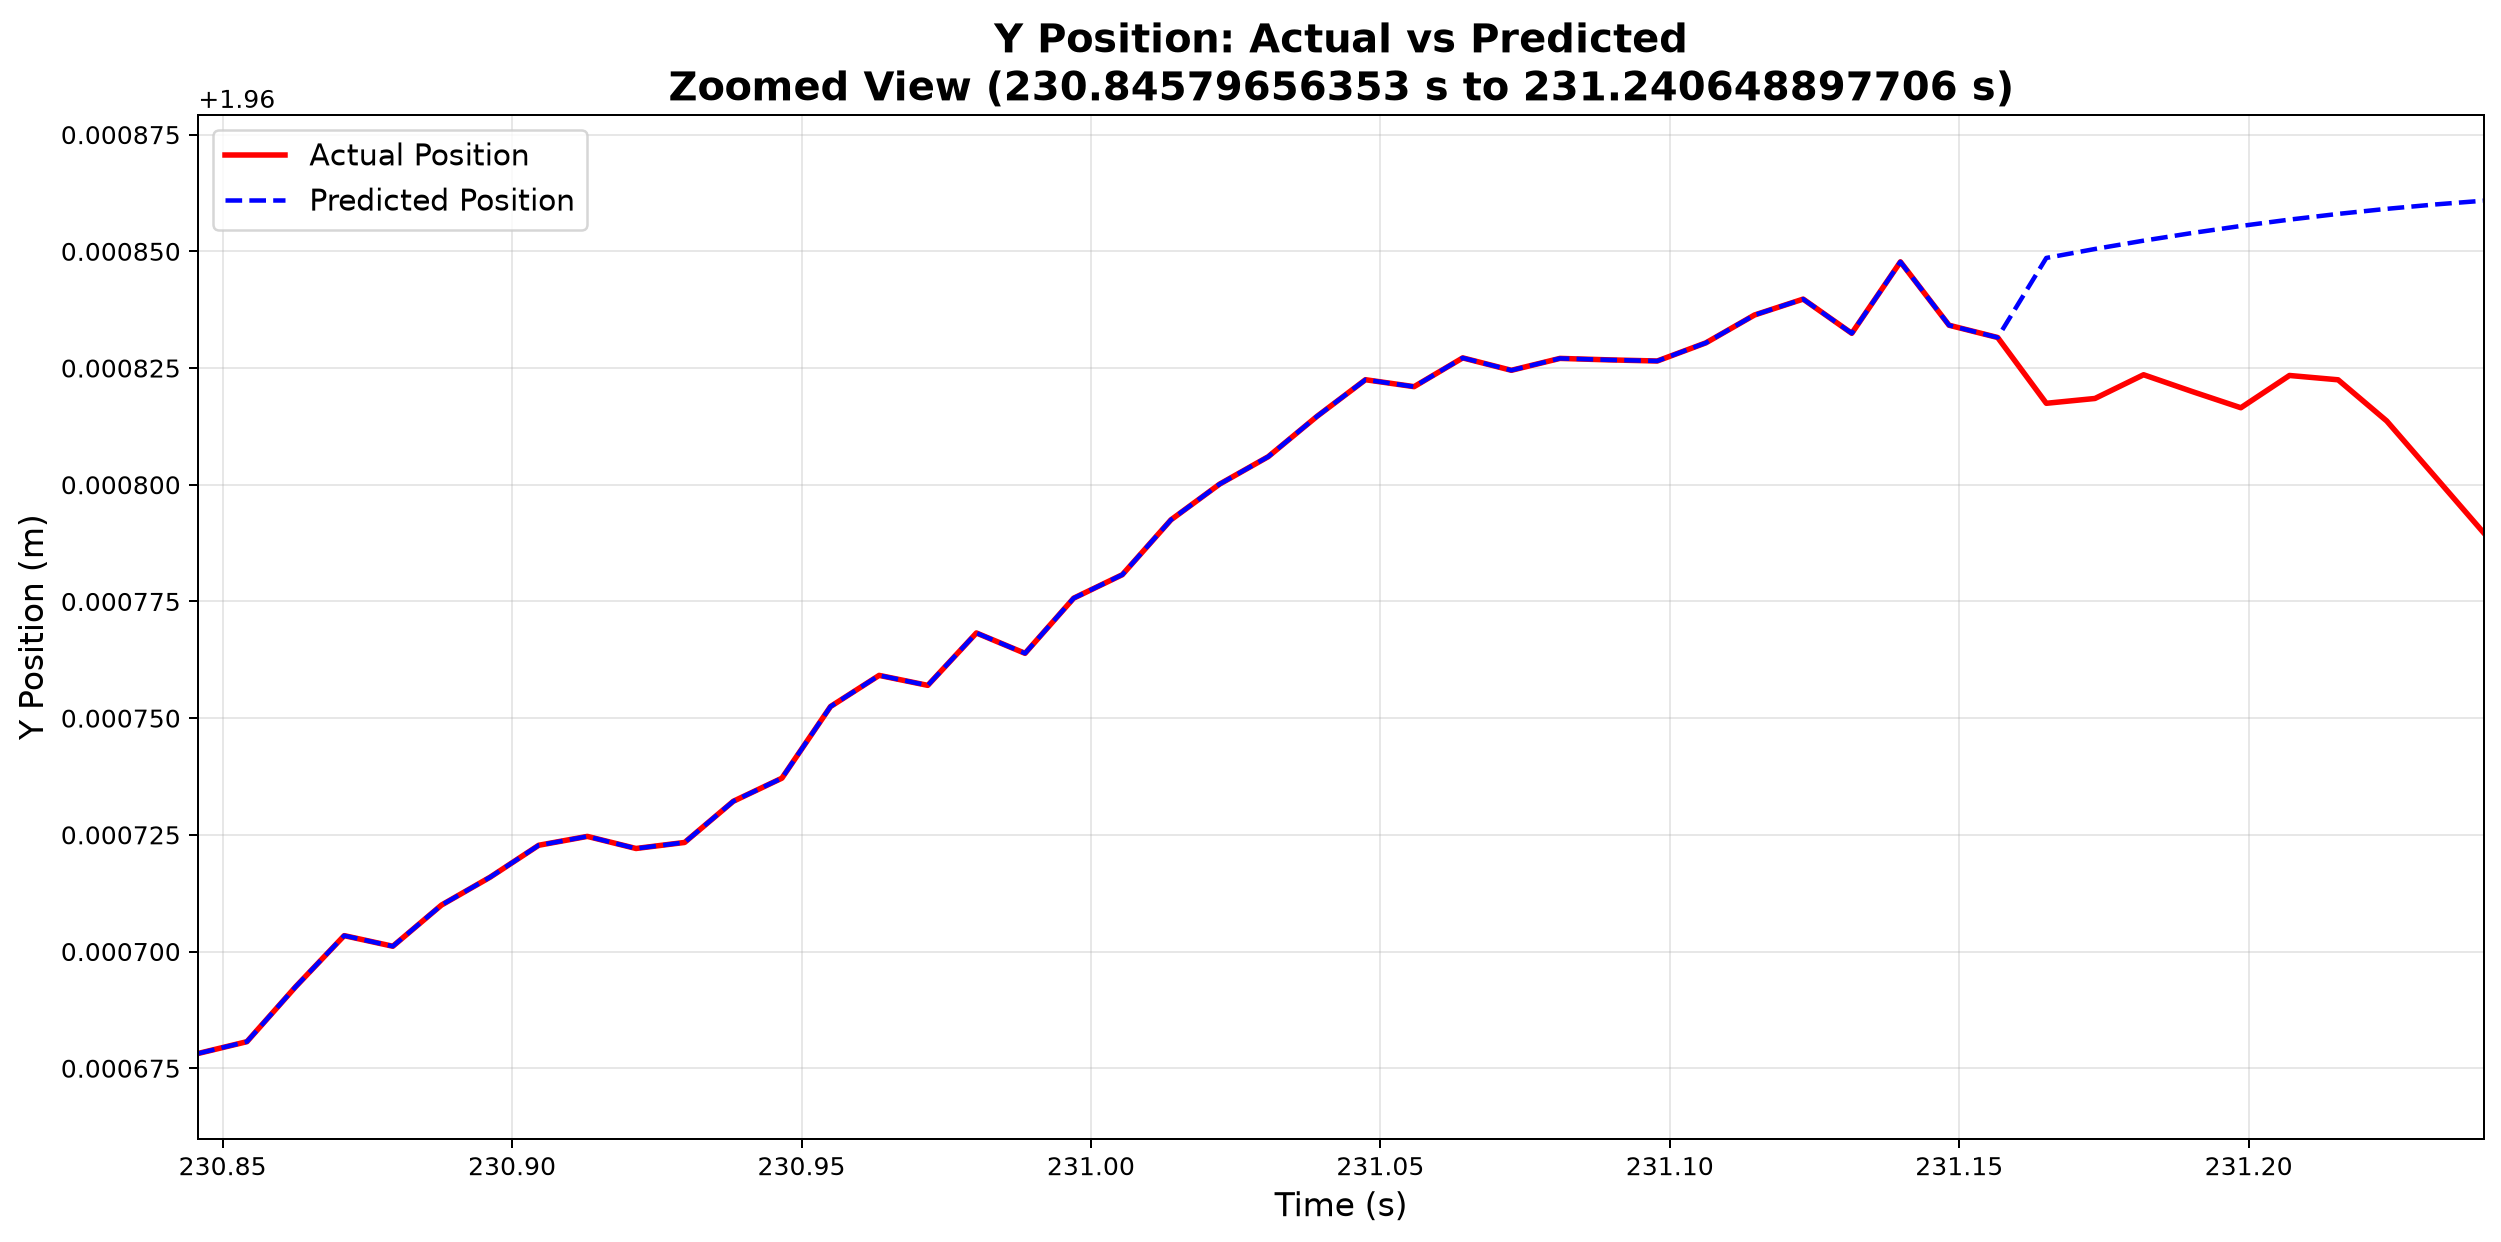

Generating Z Position plot...


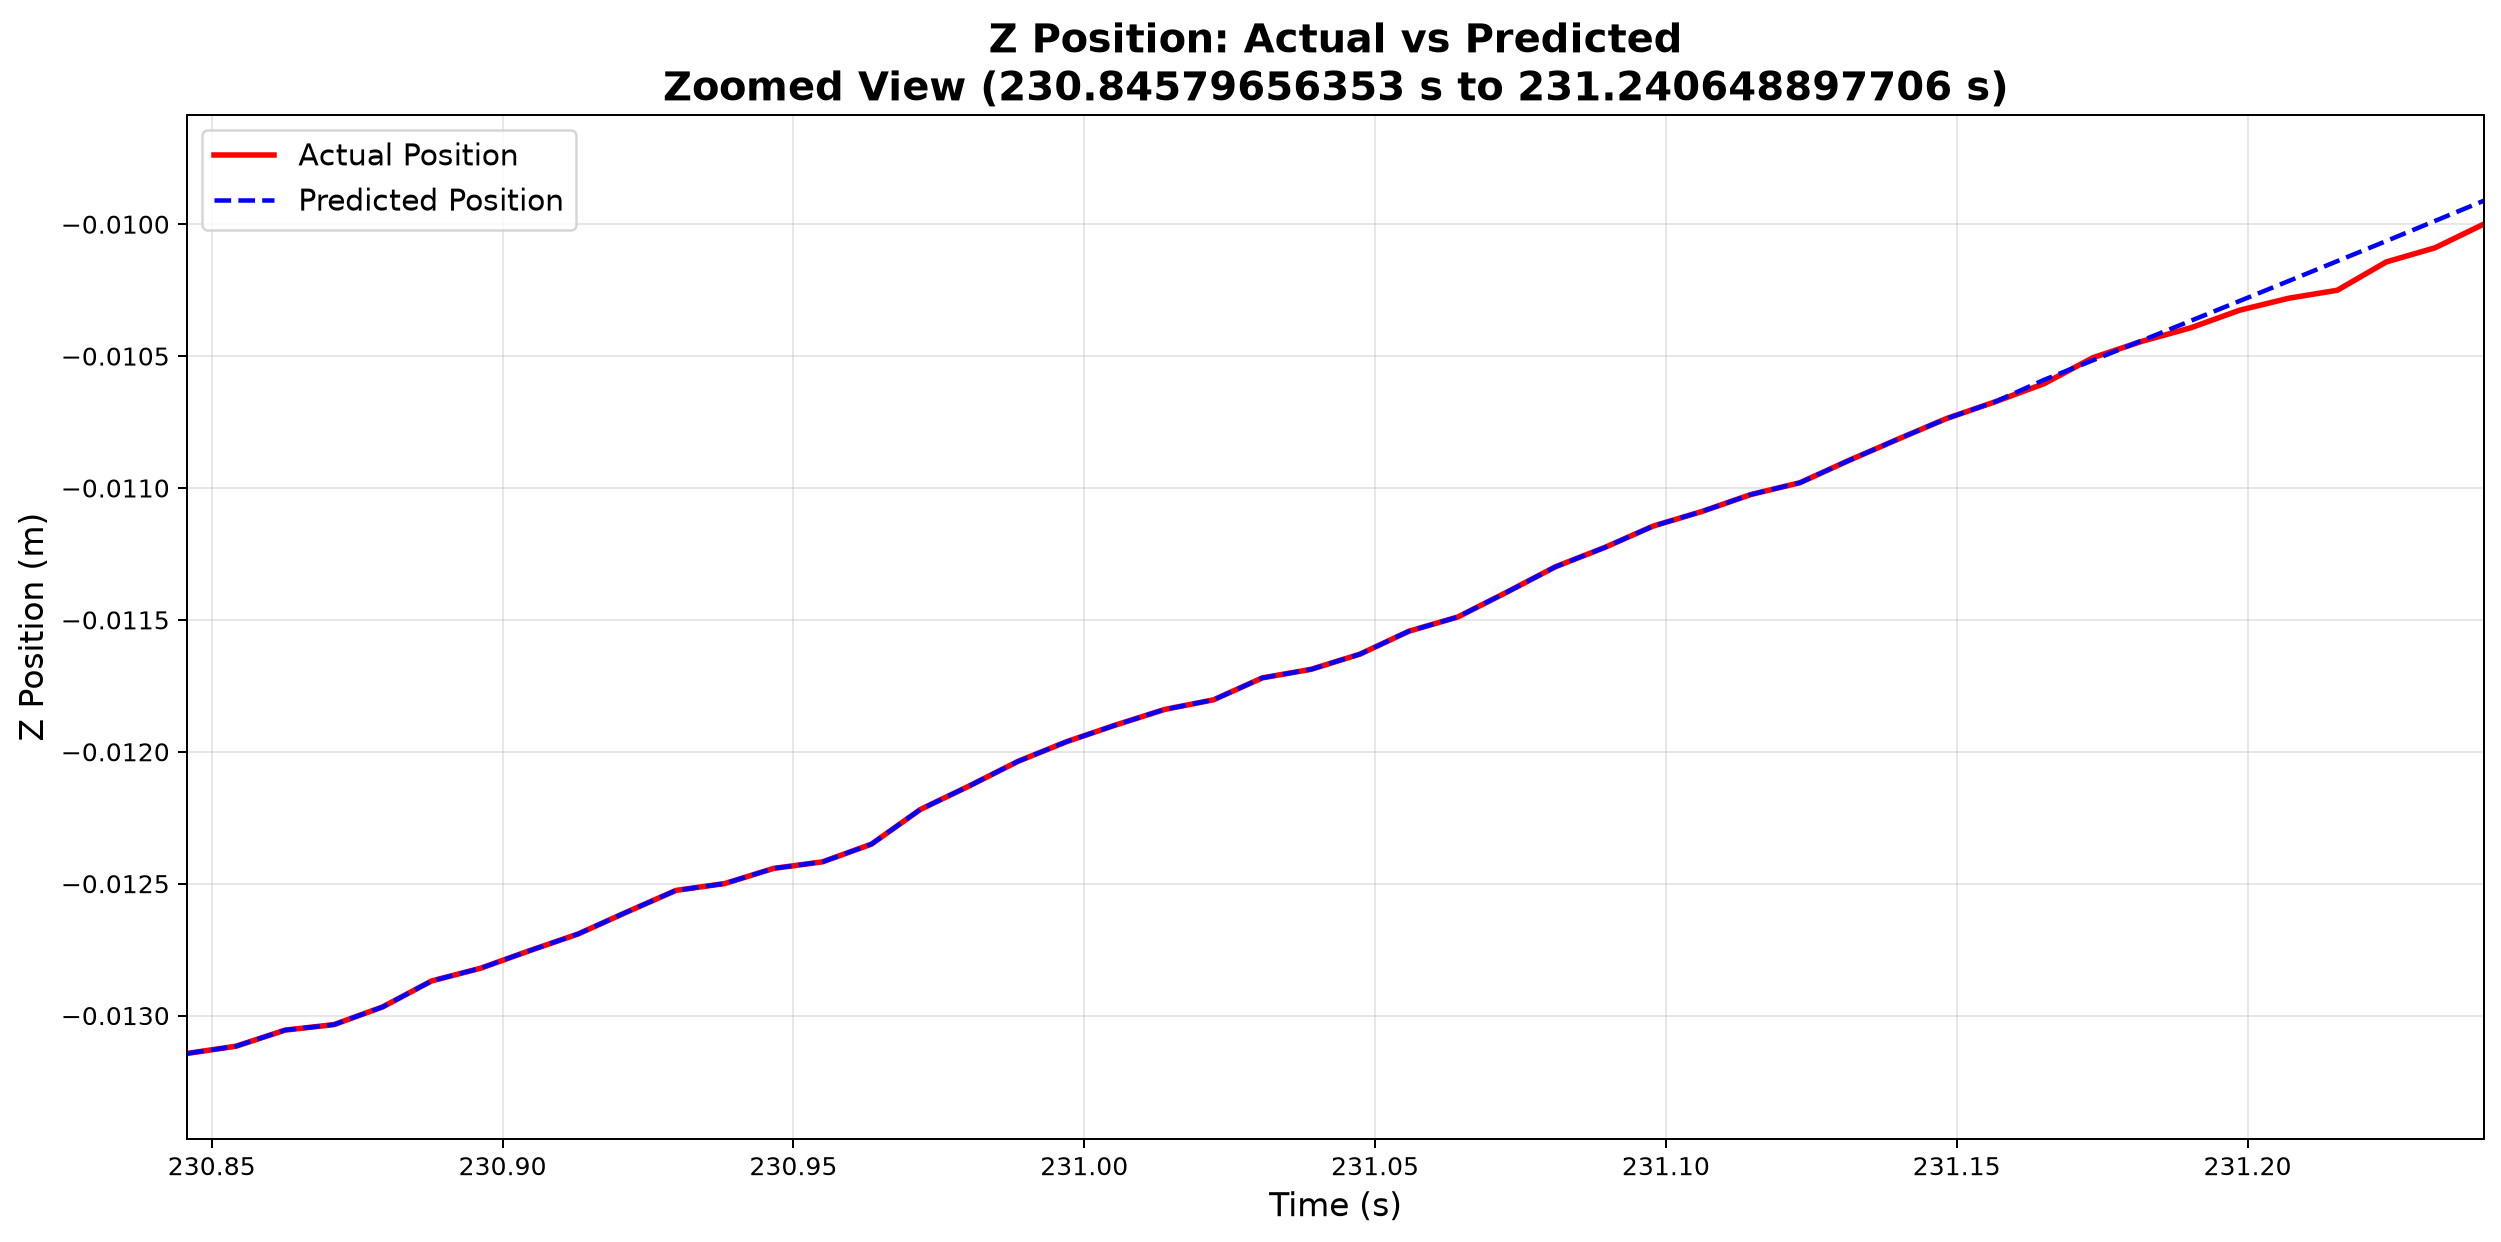

Generating Position Magnitude plot...


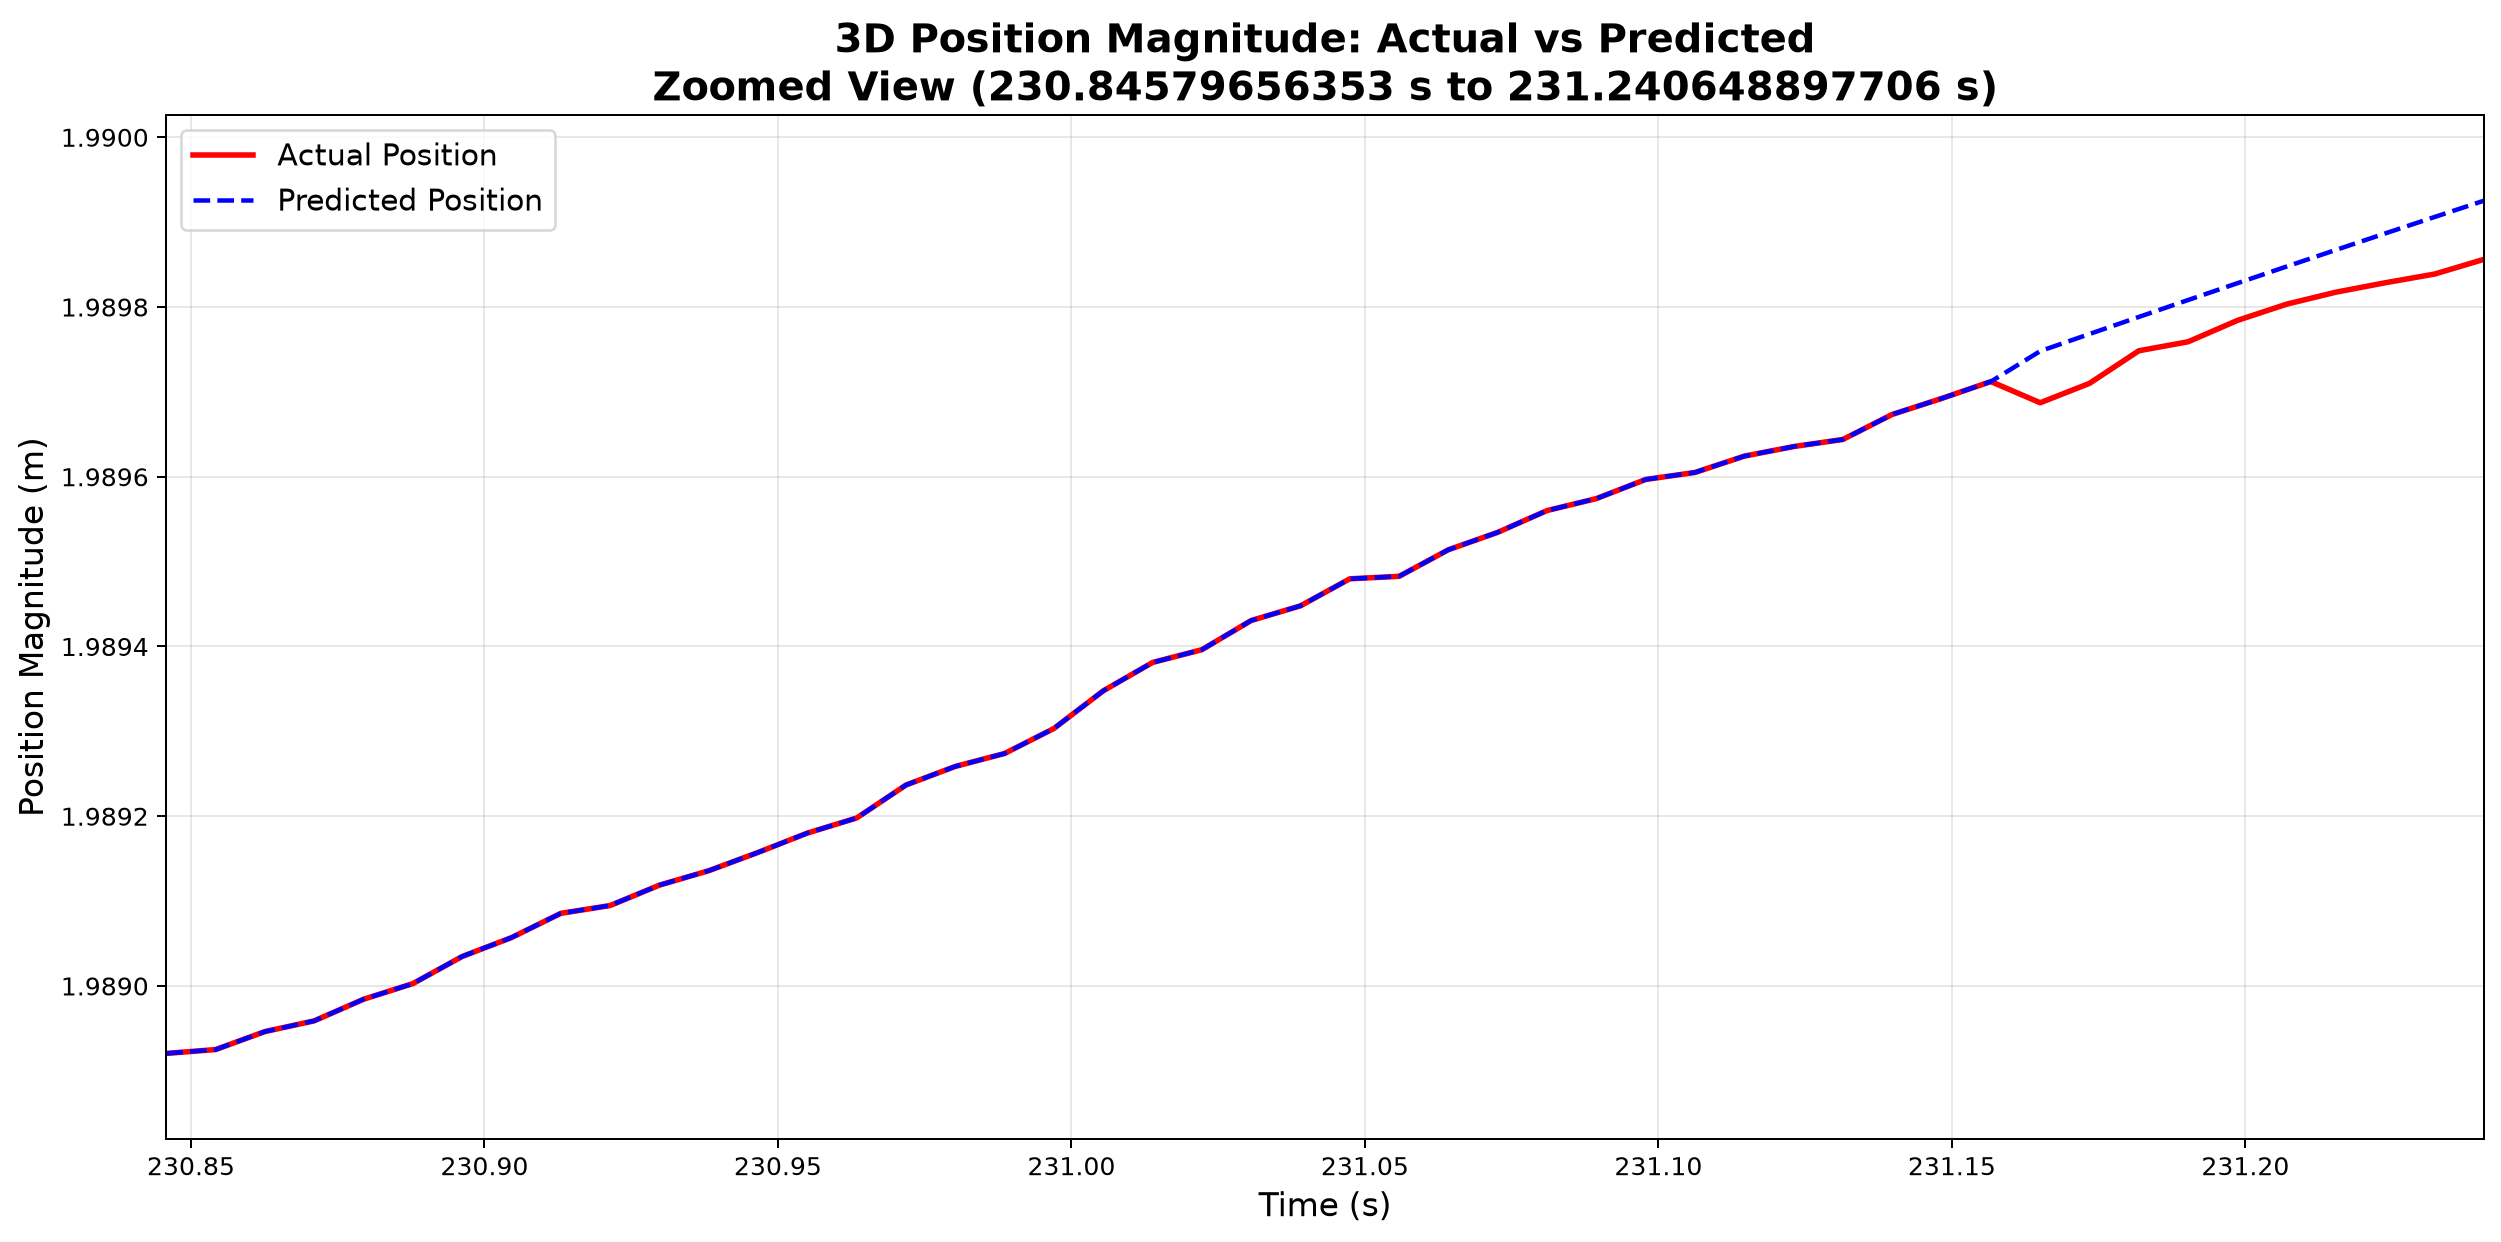


PLOTTING COMPLETE

Zoom range: 230.84579656353 s to 231.240648897706 s

Plots saved to:
C:\Users\samiu\Desktop\Kinematics\Test01_bvh_Global_RShoulder\Window Creation\Kinematic Prediction\Plotting Predictions\Best_Window_Position_Actual_vs_Pred_Plots_230.846_to_231.241s

Generated plots:
1. X Position
2. Y Position
3. Z Position
4. 3D Position Magnitude


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# USER SETTINGS
# ============================================================

INPUT_FILE = r"C:\\Users\\samiu\\Desktop\\Kinematics\\Test01_bvh_Global_RShoulder\\Window Creation\\Kinematic Prediction\\RShoulder_KinematicPrediction_Report.xlsx"

# ------------------------------------------------------------
# ZOOM RANGE
# Change these values whenever you want to inspect
# another part of the motion.
# ------------------------------------------------------------

START_TIME = 230.84579656353 # Worst window but only prediction timestamps 178.204419415736 # 230.84579656353 # Worst 177.817968     # Best 230.84579656353 
END_TIME = 231.240648897706 # Worst window but only prediction timestamps 178.29683166416 # 231.240648897706 # Worst 178.296832       # Best 231.240648897706


# ============================================================
# LOAD DATA
# ============================================================

print("Loading dataset...")

df = pd.read_excel(INPUT_FILE)

print(f"Total samples loaded: {len(df)}")
print(f"Available time range: {df['Time (s)'].min():.4f} s "
      f"to {df['Time (s)'].max():.4f} s")


# ============================================================
# REQUIRED COLUMN NAMES
# ============================================================

TIME_COL = "Time (s)"

ACTUAL_X = "X Position (m)"
ACTUAL_Y = "Y Position (m)"
ACTUAL_Z = "Z Position (m)"

PRED_X = "Predicted X Position (m)"
PRED_Y = "Predicted Y Position (m)"
PRED_Z = "Predicted Z Position (m)"


# ============================================================
# VALIDATE COLUMNS
# ============================================================

required_columns = [
    TIME_COL,

    ACTUAL_X,
    ACTUAL_Y,
    ACTUAL_Z,

    PRED_X,
    PRED_Y,
    PRED_Z
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("\nERROR: The following required columns were not found:")
    for col in missing_columns:
        print(f"  - {col}")

    print("\nAvailable columns in the Excel file:")
    for col in df.columns:
        print(f"  - {col}")

    raise SystemExit


# ============================================================
# EXTRACT ZOOMED DATA
# ============================================================

zoom_df = df[
    (df[TIME_COL] >= START_TIME) &
    (df[TIME_COL] <= END_TIME)
].copy()


if zoom_df.empty:
    raise ValueError(
        f"No data found between {START_TIME} s and {END_TIME} s."
    )


print("\nZoom range:")
print(f"Start time: {START_TIME} s")
print(f"End time  : {END_TIME} s")
print(f"Samples   : {len(zoom_df)}")


# ============================================================
# CALCULATE POSITION MAGNITUDES
# ============================================================

# Actual 3D position magnitude
zoom_df["Actual Position Magnitude"] = np.sqrt(
    zoom_df[ACTUAL_X] ** 2 +
    zoom_df[ACTUAL_Y] ** 2 +
    zoom_df[ACTUAL_Z] ** 2
)


# Predicted 3D position magnitude
zoom_df["Predicted Position Magnitude"] = np.sqrt(
    zoom_df[PRED_X] ** 2 +
    zoom_df[PRED_Y] ** 2 +
    zoom_df[PRED_Z] ** 2
)


# ============================================================
# FUNCTION: AUTOMATIC Y-AXIS LIMITS
# ============================================================

def get_dynamic_ylim(actual, predicted, padding_ratio=0.10):

    values = np.concatenate([
        np.asarray(actual),
        np.asarray(predicted)
    ])

    values = values[np.isfinite(values)]

    minimum = np.min(values)
    maximum = np.max(values)

    data_range = maximum - minimum

    # Handle nearly constant data
    if data_range < 1e-12:

        padding = max(
            abs(maximum) * padding_ratio,
            1e-6
        )

    else:

        padding = data_range * padding_ratio

    return (
        minimum - padding,
        maximum + padding
    )


# ============================================================
# FUNCTION: CREATE POSITION PLOT
# ============================================================

def plot_actual_vs_predicted(
        time,
        actual,
        predicted,
        title,
        ylabel,
        filename
):

    fig, ax = plt.subplots(
        figsize=(14, 7),
        dpi=180
    )

    # --------------------------------------------------------
    # ACTUAL POSITION
    # --------------------------------------------------------

    ax.plot(
        time,
        actual,
        color="red",
        linewidth=2.2,
        label="Actual Position"
    )


    # --------------------------------------------------------
    # PREDICTED POSITION
    # --------------------------------------------------------

    ax.plot(
        time,
        predicted,
        color="blue",
        linewidth=1.8,
        linestyle="--",
        label="Predicted Position"
    )


    # --------------------------------------------------------
    # AXIS LIMITS
    # --------------------------------------------------------

    ymin, ymax = get_dynamic_ylim(
        actual,
        predicted
    )

    ax.set_ylim(
        ymin,
        ymax
    )

    ax.set_xlim(
        START_TIME,
        END_TIME
    )


    # --------------------------------------------------------
    # LABELS
    # --------------------------------------------------------

    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Time (s)",
        fontsize=13
    )

    ax.set_ylabel(
        ylabel,
        fontsize=13
    )


    # --------------------------------------------------------
    # GRID AND LEGEND
    # --------------------------------------------------------

    ax.grid(
        True,
        alpha=0.3
    )

    ax.legend(
        fontsize=12
    )


    # --------------------------------------------------------
    # LAYOUT
    # --------------------------------------------------------

    plt.tight_layout()

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# CREATE OUTPUT DIRECTORY
# ============================================================

input_path = Path(INPUT_FILE)

output_dir = (
    input_path.parent / "Plotting Predictions" /
    #f"Worst_Window_Position_Actual_vs_Pred_Plots_{START_TIME:.3f}_to_{END_TIME:.3f}s"
    f"Best_Window_Position_Actual_vs_Pred_Plots_{START_TIME:.3f}_to_{END_TIME:.3f}s"
)

output_dir.mkdir(
    exist_ok=True
)


# ============================================================
# X POSITION
# ============================================================

print("\nGenerating X Position plot...")

plot_actual_vs_predicted(

    time=zoom_df[TIME_COL],

    actual=zoom_df[ACTUAL_X],

    predicted=zoom_df[PRED_X],

    title=(
        f"X Position: Actual vs Predicted\n"
        f"Zoomed View ({START_TIME} s to {END_TIME} s)"
    ),

    ylabel="X Position (m)",

    filename=(
        output_dir /
        "X_Plots.png"
    )
)


# ============================================================
# Y POSITION
# ============================================================

print("Generating Y Position plot...")

plot_actual_vs_predicted(

    time=zoom_df[TIME_COL],

    actual=zoom_df[ACTUAL_Y],

    predicted=zoom_df[PRED_Y],

    title=(
        f"Y Position: Actual vs Predicted\n"
        f"Zoomed View ({START_TIME} s to {END_TIME} s)"
    ),

    ylabel="Y Position (m)",

    filename=(
        output_dir /
        "Y_Plots.png"
    )
)


# ============================================================
# Z POSITION
# ============================================================

print("Generating Z Position plot...")

plot_actual_vs_predicted(

    time=zoom_df[TIME_COL],

    actual=zoom_df[ACTUAL_Z],

    predicted=zoom_df[PRED_Z],

    title=(
        f"Z Position: Actual vs Predicted\n"
        f"Zoomed View ({START_TIME} s to {END_TIME} s)"
    ),

    ylabel="Z Position (m)",

    filename=(
        output_dir /
        "Z_Plots.png"
    )
)


# ============================================================
# 3D POSITION MAGNITUDE
# ============================================================

print("Generating Position Magnitude plot...")

plot_actual_vs_predicted(

    time=zoom_df[TIME_COL],

    actual=zoom_df["Actual Position Magnitude"],

    predicted=zoom_df["Predicted Position Magnitude"],

    title=(
        f"3D Position Magnitude: Actual vs Predicted\n"
        f"Zoomed View ({START_TIME} s to {END_TIME} s)"
    ),

    ylabel="Position Magnitude (m)",

    filename=(
        output_dir /
        "Position_Magnitude_Plots.png"
    )
)


# ============================================================
# COMPLETION MESSAGE
# ============================================================

print("\n" + "=" * 70)
print("PLOTTING COMPLETE")
print("=" * 70)

print(f"\nZoom range: {START_TIME} s to {END_TIME} s")

print("\nPlots saved to:")

print(output_dir)

print("\nGenerated plots:")

print("1. X Position")
print("2. Y Position")
print("3. Z Position")
print("4. 3D Position Magnitude")

print("=" * 70)